In [1]:
import pandas as pd

In [5]:
sezoane = ['1617', '1718', '1819', '1920', '2021', '2122', '2223', '2324', '2425', '2526', '2627']
url = "https://www.football-data.co.uk/mmz4281/{}/E0.csv"

df = pd.concat([pd.read_csv(url.format(s)).assign(Sezon=s) for s in sezoane])
df = df[['Sezon', 'Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR']]

df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, format='mixed')
print(df['FTR'].value_counts(normalize=True))

C:\Users\asus\AppData\Local\Temp\ipykernel_13844\1507512748.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = pd.concat([pd.read_csv(url.format(s)).assign(Sezon=s) for s in sezoane])


FTR
H    0.445478
A    0.321189
D    0.233333
Name: proportion, dtype: float64


In [6]:
print(df['Date'].isna().sum())
print(df['Date'].min(), df['Date'].max())

0
2016-08-13 00:00:00 2026-10-19 00:00:00


In [7]:
import numpy as np
from scipy.stats import poisson
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import log_loss, accuracy_score

def lung(m):
    a = pd.DataFrame({"team": m["HomeTeam"], "opponent": m["AwayTeam"], "home": 1, "goals": m["FTHG"]})
    b = pd.DataFrame({"team": m["AwayTeam"], "opponent": m["HomeTeam"], "home": 0, "goals": m["FTAG"]})
    return pd.concat([a, b], ignore_index=True)

def matrice(g):
    X = pd.get_dummies(g[["team", "opponent"]]).astype(float)
    X["home"] = g["home"].values
    return X

def sezoane_df(lista):
    return df[df["Sezon"].isin(lista)].dropna(subset=["FTHG", "FTAG"]).reset_index(drop=True)

In [8]:
def prob_meciuri(model, coloane, meciuri):
    n = len(meciuri)
    Xh = pd.DataFrame(0.0, index=range(n), columns=coloane)
    Xa = pd.DataFrame(0.0, index=range(n), columns=coloane)
    for i, (h, a) in enumerate(zip(meciuri["HomeTeam"], meciuri["AwayTeam"])):
        for X, t, o in [(Xh, h, a), (Xa, a, h)]:
            if "team_" + t in coloane: X.loc[i, "team_" + t] = 1
            if "opponent_" + o in coloane: X.loc[i, "opponent_" + o] = 1
    Xh["home"] = 1
    lh, la = model.predict(Xh), model.predict(Xa)

    g = np.arange(10)
    m = poisson.pmf(g, lh[:, None])[:, :, None] * poisson.pmf(g, la[:, None])[:, None, :]
    p = np.column_stack([np.tril(m, -1).sum(axis=(1, 2)), np.trace(m, axis1=1, axis2=2), np.triu(m, 1).sum(axis=(1, 2))])
    return p / p.sum(axis=1, keepdims=True)

In [9]:
# 1) Alegerea lui alpha: antrenez pe 2022/23 + 2023/24 si validez pe 2024/25
train_v = sezoane_df(["2223", "2324"])
val = sezoane_df(["2425"])
y_val = val["FTR"].map({"H": 0, "D": 1, "A": 2}).values
Xv = matrice(lung(train_v))

rezultate = {}
for alpha in [0.001, 0.005, 0.01, 0.05, 0.1]:
    m_v = PoissonRegressor(alpha=alpha, max_iter=1000).fit(Xv, lung(train_v)["goals"])
    p = prob_meciuri(m_v, Xv.columns, val)
    rezultate[alpha] = log_loss(y_val, p, labels=[0, 1, 2])
    print(alpha, round(rezultate[alpha], 4), round(accuracy_score(y_val, p.argmax(axis=1)), 3))

best_alpha = min(rezultate, key=rezultate.get)
print("Alpha ales pe validare:", best_alpha)

0.001 1.0241 0.5
0.005 1.024 0.5
0.01 1.0242 0.5
0.05 1.0301 0.487
0.1 1.0379 0.471
Alpha ales pe validare: 0.005


In [10]:
# 2) Testul final, o singura data: antrenez pe 2023/24 + 2024/25 si testez pe 2025/26
train = sezoane_df(["2324", "2425"])
test = sezoane_df(["2526"])
print(len(train), len(test))

y = test["FTR"].map({"H": 0, "D": 1, "A": 2}).values
g_train = lung(train)
Xt = matrice(g_train)
m_t = PoissonRegressor(alpha=best_alpha, max_iter=1000).fit(Xt, g_train["goals"])
p_model = prob_meciuri(m_t, Xt.columns, test)
print("Model:", round(log_loss(y, p_model, labels=[0, 1, 2]), 4), round(accuracy_score(y, p_model.argmax(axis=1)), 3))

760 380
Model: 1.0312 0.474


In [11]:
cote = pd.read_csv(url.format("2526"))[["HomeTeam", "AwayTeam", "AvgH", "AvgD", "AvgA"]]
test_c = test.merge(cote, on=["HomeTeam", "AwayTeam"], how="left")
print(test_c[["AvgH", "AvgD", "AvgA"]].isna().sum().sum())

imp = 1 / test_c[["AvgH", "AvgD", "AvgA"]].values
p_case = imp / imp.sum(axis=1, keepdims=True)
print("Case de pariuri:", round(log_loss(y, p_case), 4), round(accuracy_score(y, p_case.argmax(axis=1)), 3))

0
Case de pariuri: 1.0153 0.495


Baseline: 1.0852 0.426
[1.085174234704821, 1.0312021890120828, 1.0152523829672504]


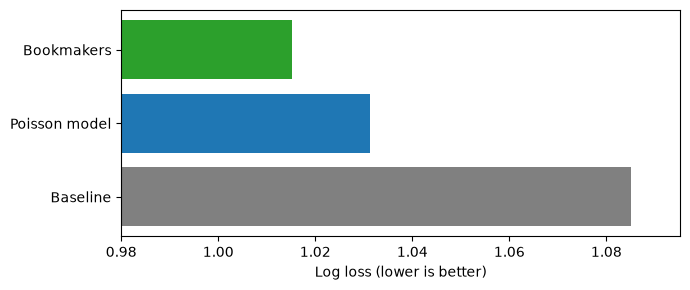

In [12]:
import os
import matplotlib.pyplot as plt

f = train["FTR"].value_counts(normalize=True)[["H", "D", "A"]].values
p_base = np.tile(f, (len(test), 1))
print("Baseline:", round(log_loss(y, p_base), 4), round(accuracy_score(y, np.zeros(len(y))), 3))

nume = ["Baseline", "Poisson model", "Bookmakers"]
valori = [log_loss(y, p_base), log_loss(y, p_model, labels=[0, 1, 2]), log_loss(y, p_case)]
print(valori)

plt.figure(figsize=(7, 3))
plt.barh(nume, valori, color=["grey", "tab:blue", "tab:green"])
plt.xlim(0.98, max(valori) + 0.01)
plt.xlabel("Log loss (lower is better)")
plt.tight_layout()
os.makedirs("imagini", exist_ok=True)
plt.savefig("imagini/evaluare.png", dpi=150)

In [13]:
# Modelul final pentru sezonul 2026/27, cu acelasi alpha
recent = df[df["Date"] >= "2024-08-01"].dropna(subset=["FTHG", "FTAG"])
goals = lung(recent)
print(len(goals))
print(goals.columns.tolist())
print(goals.isna().sum().sum())  # trebuie sa fie 0

1660
['team', 'opponent', 'home', 'goals']
0


In [14]:
X = matrice(goals)
coloane = X.columns

reg = PoissonRegressor(alpha=best_alpha, max_iter=1000).fit(X, goals["goals"])
print(dict(zip(coloane, reg.coef_))["home"])

0.14358896414647881


In [15]:
def prezice(gazda, oaspete):
    rand = pd.DataFrame(0.0, index=[0, 1], columns=coloane)
    rand.loc[0, ["team_" + gazda, "opponent_" + oaspete, "home"]] = 1
    rand.loc[1, ["team_" + oaspete, "opponent_" + gazda]] = 1
    lg, lo = reg.predict(rand)
    m = np.outer(poisson.pmf(range(10), lg), poisson.pmf(range(10), lo))
    return {"H": round(np.tril(m, -1).sum(), 3), "D": round(np.trace(m), 3), "A": round(np.triu(m, 1).sum(), 3)}

prezice("Liverpool", "Man City")

{'H': np.float64(0.365), 'D': np.float64(0.237), 'A': np.float64(0.397)}

In [16]:
sezon = df[df["Sezon"] == "2627"].dropna(subset=["FTHG", "FTAG"])
echipe = sorted(set(sezon["HomeTeam"]) | set(sezon["AwayTeam"]))
jucate = set(zip(sezon["HomeTeam"], sezon["AwayTeam"]))

ramase = [(h, a) for h in echipe for a in echipe if h != a and (h, a) not in jucate]
print(len(echipe), len(jucate), len(ramase))

20 70 310


In [17]:
pred = pd.DataFrame([{"Gazda": h, "Oaspete": a, **prezice(h, a)} for h, a in ramase])
pred["Favorit"] = pred[["H", "D", "A"]].idxmax(axis=1)
pred.sort_values("H", ascending=False)

,Gazda,Oaspete,H,D,A,Favorit
8,Arsenal,Ipswich,0.820,0.122,0.057,H
212,Liverpool,Ipswich,0.783,0.130,0.085,H
84,Chelsea,Ipswich,0.731,0.156,0.112,H
69,Brighton,Ipswich,0.730,0.156,0.114,H
56,Brentford,Ipswich,0.699,0.168,0.132,H
...,...,...,...,...,...,...
176,Ipswich,Chelsea,0.170,0.192,0.638,A
104,Coventry,Man City,0.162,0.201,0.637,A
93,Coventry,Arsenal,0.141,0.214,0.645,A
182,Ipswich,Man City,0.103,0.150,0.746,A


In [18]:
puncte0 = {e: 0 for e in echipe}
gd0 = {e: 0 for e in echipe}
for _, r in sezon.iterrows():
    h, a, gh, ga = r["HomeTeam"], r["AwayTeam"], r["FTHG"], r["FTAG"]
    puncte0[h] += 3 if gh > ga else (1 if gh == ga else 0)
    puncte0[a] += 3 if ga > gh else (1 if gh == ga else 0)
    gd0[h] += gh - ga
    gd0[a] += ga - gh

In [19]:
lam = []
for h, a in ramase:
    rand = pd.DataFrame(0.0, index=[0, 1], columns=coloane)
    rand.loc[0, ["team_" + h, "opponent_" + a, "home"]] = 1
    rand.loc[1, ["team_" + a, "opponent_" + h]] = 1
    lam.append(reg.predict(rand))
lam = np.array(lam)
print(lam.shape)

(310, 2)


In [20]:
N = 10000
rng = np.random.default_rng(42)
gh = rng.poisson(lam[:, 0], size=(N, len(ramase)))
ga = rng.poisson(lam[:, 1], size=(N, len(ramase)))

idx = {e: i for i, e in enumerate(echipe)}
H = np.array([idx[h] for h, a in ramase])
A = np.array([idx[a] for h, a in ramase])

In [21]:
pts = np.tile([puncte0[e] for e in echipe], (N, 1)).astype(float)
gd = np.tile([gd0[e] for e in echipe], (N, 1)).astype(float)

for j in range(len(ramase)):
    pts[:, H[j]] += np.where(gh[:, j] > ga[:, j], 3, np.where(gh[:, j] == ga[:, j], 1, 0))
    pts[:, A[j]] += np.where(ga[:, j] > gh[:, j], 3, np.where(gh[:, j] == ga[:, j], 1, 0))
    gd[:, H[j]] += gh[:, j] - ga[:, j]
    gd[:, A[j]] += ga[:, j] - gh[:, j]

In [22]:
scor = pts + gd / 1000
loc = (-scor).argsort(axis=1).argsort(axis=1) + 1

rez = pd.DataFrame({
    "Puncte medii": pts.mean(axis=0),
    "Titlu %": (loc == 1).mean(axis=0) * 100,
    "Top 4 %": (loc <= 4).mean(axis=0) * 100,
    "Retrogradare %": (loc >= 18).mean(axis=0) * 100,
}, index=echipe).sort_values("Puncte medii", ascending=False).round(1)
rez

,Puncte medii,Titlu %,Top 4 %,Retrogradare %
Man City,78.8,48.3,98.1,0.0
Arsenal,78.7,46.1,98.1,0.0
Liverpool,65.3,2.6,62.6,0.0
Brighton,63.7,1.8,55.3,0.0
Chelsea,62.0,0.9,42.9,0.1
Brentford,54.7,0.0,11.4,1.0
Aston Villa,52.3,0.0,6.1,3.0
Newcastle,51.8,0.0,5.5,3.3
Leeds,50.8,0.0,4.5,3.9
Hull,50.6,0.0,3.7,4.3


In [ ]:
# Salvez tabelul simularii ca imagine pentru README
tabel = rez.rename(columns={"Puncte medii": "Avg points", "Titlu %": "Title %",
                            "Top 4 %": "Top 4 %", "Retrogradare %": "Relegation %"})
fig, ax = plt.subplots(figsize=(6.5, 0.27 * len(tabel) + 0.3))
ax.axis("off")
t = ax.table(cellText=tabel.values, rowLabels=[f"{i + 1}. {e}" for i, e in enumerate(tabel.index)],
             colLabels=tabel.columns, loc="center", cellLoc="center")
t.scale(1, 1.3)
for (r, c), cell in t.get_celld().items():
    cell.set_edgecolor("#dddddd")
    if r == 0:
        cell.set_facecolor("#38003c")
        cell.get_text().set_color("white")
        cell.get_text().set_weight("bold")
    elif c == -1:
        cell.get_text().set_ha("left")
        cell.set_facecolor("#f4f4f4")
    elif c == 1 and tabel.iloc[r - 1, 1] >= 10:
        cell.set_facecolor("#c8e6c9")
    elif c == 3 and tabel.iloc[r - 1, 3] >= 20:
        cell.set_facecolor("#ffcdd2")
plt.tight_layout()
os.makedirs("imagini", exist_ok=True)
plt.savefig("imagini/simulare.png", dpi=150, bbox_inches="tight")


In [23]:
coef = pd.Series(reg.coef_, index=coloane)
print(coef[["team_Hull", "opponent_Hull", "team_Coventry", "opponent_Coventry"]])
print(goals[goals["team"].isin(["Hull", "Coventry"])].groupby("team")["goals"].agg(["count", "sum"]))

team_Hull           -0.056780
opponent_Hull       -0.171970
team_Coventry       -0.136285
opponent_Coventry    0.134580
dtype: float64
          count  sum
team                
Coventry      7    6
Hull          7    8
